# Predicting Debt Distress Among Kenyan Digital Credit Borrowers

**DSA 8401 Applied Machine Learning: Capstone Project**
Njogu Sharon Wanjiru (103511)

Digital loans such as Fuliza, M-Shwari, Tala and the Hustler Fund are quick to obtain, yet the 2024 FinAccess survey shows a rise in repayment difficulty. This notebook uses the FinAccess 2024 Household Survey to predict debt distress among digital borrowers, explain the predictions, and serve the final model through an API.

**Outcome.** Debt distress in the past 12 months is defined as a repayment problem (late, missed or no repayment) **and** a hardship sacrifice to repay (borrowing elsewhere, selling assets, cutting food spending or repossession). Requiring both conditions prevents a single late payment from counting as distress.

**Questions**
1. How prevalent is debt distress among digital borrowers, and how does it vary across groups?
2. Which model predicts it best, and does borrowing behaviour add predictive value beyond demographics (H3: a gain of at least 0.02 in PR-AUC)?
3. What drives the predictions, and does the model perform equally well across groups?

**Outline:** 1. Set-up, 2. Data extraction and outcome, 3. Data cleaning, 4. Exploratory analysis, 5. Train/test split, 6. Preprocessing, 7. Modelling, 8. Test-set evaluation, 9. Explaining the model, 10. Fairness and robustness, 11. Saving and serving the model, 12. Conclusions.

The notebook calls the project scripts (`Data/data_pipeline.py`, `Model/train.py`, `Model/evaluate.py`) step by step.

## 1. Set-up

In [1]:
# Install the project requirements into this notebook's environment (run once).
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "Notebook" else Path.cwd()
%pip install -q -r "{ROOT / 'requirements.txt'}"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, warnings
warnings.filterwarnings("ignore")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
BLUE, ORANGE, GREY = "#1F4E79", "#C55A11", "#7F7F7F"

## 2. Data extraction and outcome

The data is the FinAccess 2024 public release from the Kenya National Data Archive (KeNADA): a Stata file with 20,871 adults and 3,816 variables, of which only the required items are loaded (`load_raw`). Four features of the survey shape the analysis:

- **Survey weights:** respondents were sampled with unequal probabilities, so prevalence estimates and all model metrics are weighted.
- **Clustered sampling:** respondents in the same enumeration area are similar, so every split keeps whole clusters together.
- **Survey coding:** "don't know/refused" codes (98, 99) and skip patterns, where a blank means "not asked".
- **Leakage risk:** questions that record the consequences of default are excluded.

In [3]:
from Data.data_pipeline import load_raw, build_dataset, cluster_split

raw = load_raw()
df = build_dataset(raw)
w = df["weight"]
print(f"Respondents in the survey: {len(raw):,}")
print(f"Current digital borrowers with a valid repayment answer: {len(df):,}")
print(f"Sampling clusters: {df['cluster'].nunique():,} across {df['county'].nunique()} counties")

Respondents in the survey: 20,871
Current digital borrowers with a valid repayment answer: 7,213
Sampling clusters: 1,726 across 47 counties


In [4]:
outcome = pd.crosstab(df["late"].map({0: "Repaid on time", 1: "Late / missed / not repaid"}),
                      df["hardship"].map({0: "No hardship", 1: "Hardship sacrifice"}),
                      values=w, aggfunc="sum", normalize=True)
display(outcome.style.format("{:.1%}"))
print(f"Weighted share in debt distress (late AND hardship): {np.average(df['distress'], weights=w):.1%}")

hardship,Hardship sacrifice,No hardship
late,,
Late / missed / not repaid,36.0%,31.9%
Repaid on time,13.6%,18.5%


Weighted share in debt distress (late AND hardship): 36.0%


About two thirds of borrowers report a repayment problem, but only about a third combine it with a hardship sacrifice. As a validity check, the outcome is compared with an item it does not use: whether the borrower is very worried about repaying debts.

In [5]:
check = df.groupby("distress").apply(lambda g: np.average(g["worried"], weights=g["weight"]))
odds = lambda p: p / (1 - p)
print(f"Very worried about debt: {check[1]:.1%} of distressed vs {check[0]:.1%} of others "
      f"(odds ratio {odds(check[1]) / odds(check[0]):.2f})")

Very worried about debt: 51.9% of distressed vs 31.0% of others (odds ratio 2.40)


Distressed borrowers are far more likely to be very worried about debt, which supports the outcome definition.

## 3. Data cleaning

Cleaning is implemented in `build_dataset`. The main decisions:

| Issue | Treatment |
|---|---|
| "Don't know/refused" (98, 99) | Set to missing ("don't know" scored as incorrect for literacy items) |
| Outstanding loans never recorded as 0 | Blank means the question was skipped; coded as 0 |
| Fuliza counts of 28 to 900 outstanding loans | Keying errors; set to missing |
| Skewed counts and ratios | Capped at the 99th percentile in the model pipeline (loan counts also log-transformed) |
| 47 counties | Grouped into 8 former provinces |

Remaining missing values:

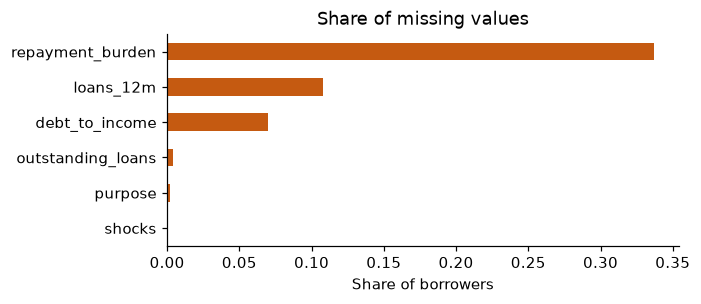

Distress rate when repayment burden is known: 43.4%, when missing: 25.9%


In [6]:
missing = df.drop(columns=["is_test"], errors="ignore").isna().mean()
missing = missing[missing > 0].sort_values()
ax = missing.plot.barh(color=ORANGE, figsize=(6, 2.5), title="Share of missing values")
ax.set_xlabel("Share of borrowers"); plt.show()
rate = df.groupby(df["repayment_burden"].isna())["distress"].mean()
print(f"Distress rate when repayment burden is known: {rate[False]:.1%}, when missing: {rate[True]:.1%}")

Repayment burden is missing for about a third of borrowers, and the distress rate differs between those with and without it, so dropping these rows would bias the sample. The pipeline instead imputes the median and adds a missing-value flag.

## 4. Exploratory analysis

### 4.1 How common is debt distress?

Debt distress among digital borrowers: 36.0% (95% CI 34.2% to 37.5%)


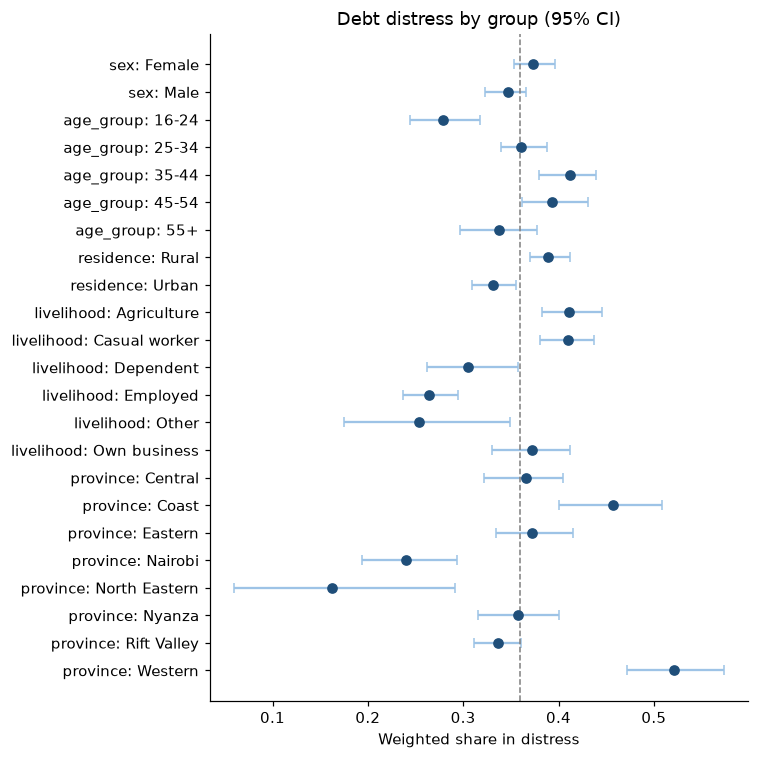

In [7]:
from Model.train import cluster_bootstrap

def weighted_rate(frame):
    return np.average(frame["distress"], weights=frame["weight"])

def rate_with_ci(frame, n_boot=300):
    # 95% interval by resampling whole clusters (the survey's sampling units)
    frame = frame.reset_index(drop=True)
    boots = [weighted_rate(frame.iloc[idx]) for idx in cluster_bootstrap(frame, n_boot)]
    return weighted_rate(frame), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

est, lo, hi = rate_with_ci(df)
print(f"Debt distress among digital borrowers: {est:.1%} (95% CI {lo:.1%} to {hi:.1%})")

rows = []
for col in ["sex", "age_group", "residence", "livelihood", "province"]:
    for level, g in df.groupby(col):
        e, l, h = rate_with_ci(g, 200)
        rows.append({"group": col, "level": level, "n": len(g), "rate": e, "low": l, "high": h})
groups = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 7))
y = np.arange(len(groups))[::-1]
ax.errorbar(groups["rate"], y, xerr=[groups["rate"] - groups["low"], groups["high"] - groups["rate"]],
            fmt="o", color=BLUE, ecolor="#9DC3E6", capsize=3)
ax.axvline(est, color=GREY, ls="--", lw=1)
ax.set_yticks(y, groups["group"] + ": " + groups["level"].astype(str))
ax.set(title="Debt distress by group (95% CI)", xlabel="Weighted share in distress")
plt.tight_layout(); plt.show()

About 36% of digital borrowers are in debt distress. Rates are highest among those aged 35 to 44, farmers and casual workers, and in Western and Coast, and lowest among the youngest borrowers and salaried workers, and in Nairobi and North Eastern. Rates for men and women are similar.

### 4.2 Distress and borrowing behaviour

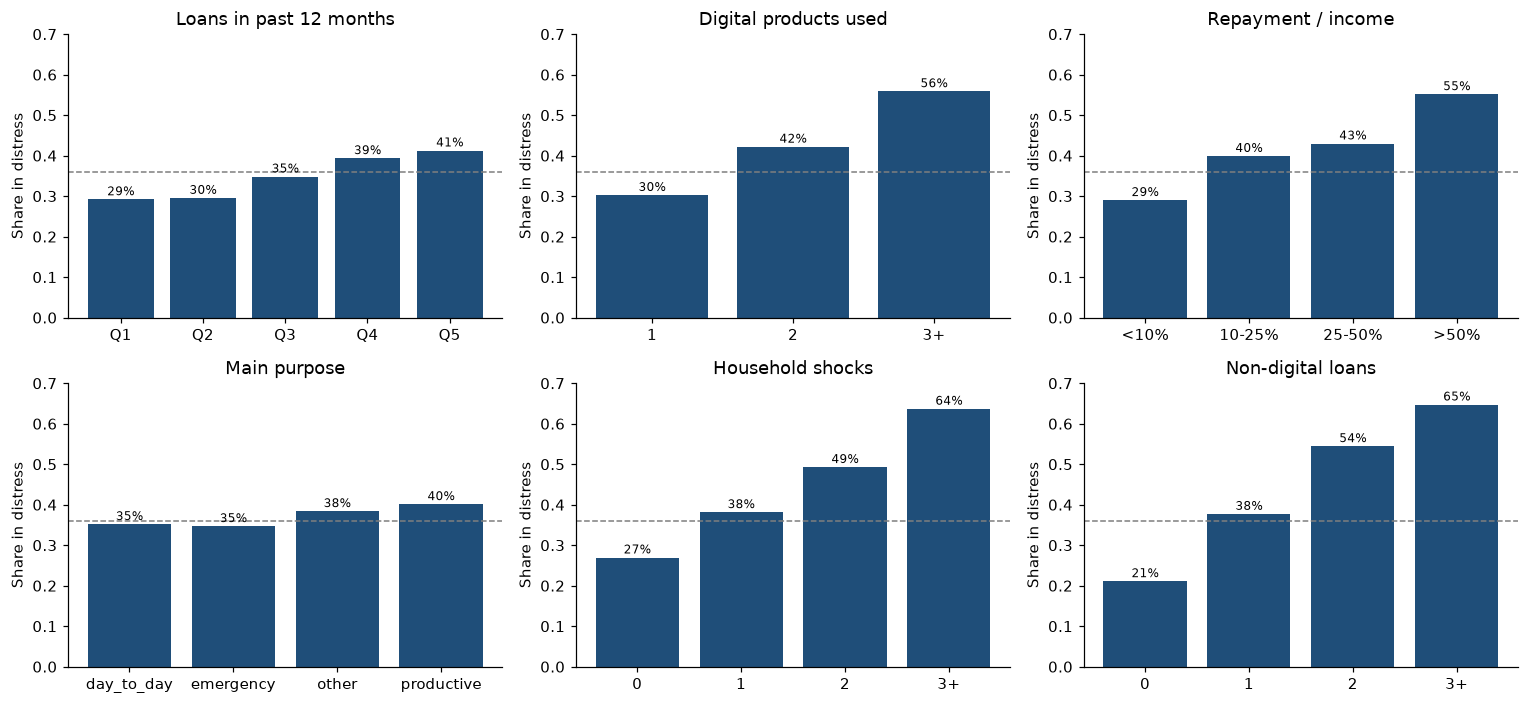

In [8]:
eda = df.copy()
eda["Loans in past 12 months"] = pd.qcut(eda["loans_12m"].rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
eda["Digital products used"] = eda["n_products"].clip(upper=3).astype(str).replace({"3": "3+"})
eda["Repayment / income"] = pd.cut(eda["repayment_burden"], [-0.01, 0.1, 0.25, 0.5, np.inf],
                                   labels=["<10%", "10-25%", "25-50%", ">50%"])
eda["Household shocks"] = eda["shocks"].clip(upper=3).astype("Int64").astype(str).replace({"3": "3+"})
eda["Non-digital loans"] = eda["nondigital_loans"].clip(upper=3).astype(str).replace({"3": "3+"})
eda["Main purpose"] = eda["purpose"]

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, col in zip(axes.ravel(), ["Loans in past 12 months", "Digital products used", "Repayment / income",
                                   "Main purpose", "Household shocks", "Non-digital loans"]):
    r = eda.dropna(subset=[col]).groupby(col, observed=True).apply(weighted_rate)
    ax.bar(r.index.astype(str), r.values, color=BLUE)
    ax.axhline(est, color=GREY, ls="--", lw=1)
    ax.set(title=col, ylim=(0, 0.7), ylabel="Share in distress")
    for i, v in enumerate(r.values):
        ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

Distress rises with the number of loans, the number of products, repayment burden, household shocks and, most steeply, the number of non-digital credit products (SACCO, chama, shopkeeper, family and other sources). Borrowing for productive purposes is associated with slightly *higher* distress than borrowing for day-to-day needs. These are unadjusted comparisons; the models consider all factors jointly.

## 5. Train/test split

Twenty percent of survey clusters in each county are held out as the test set. Whole clusters are assigned to one side, so neighbours never appear in both sets, and every county appears in both. The test set is used once, in Section 8.

In [9]:
df["is_test"] = cluster_split(df)
train, test = df[~df["is_test"]].reset_index(drop=True), df[df["is_test"]].reset_index(drop=True)
summary = df.groupby("is_test").agg(borrowers=("distress", "size"), clusters=("cluster", "nunique"),
                                    counties=("county", "nunique"), distress_rate=("distress", "mean"))
summary.index = ["Train", "Test"]
display(summary)
print("Clusters in both sets:", len(set(train["cluster"]) & set(test["cluster"])))

,borrowers,clusters,counties,distress_rate
Train,5812,1377,47,0.375
Test,1401,349,47,0.375


Clusters in both sets: 0


## 6. Preprocessing

Each model is a scikit-learn `Pipeline`: a `ColumnTransformer` followed by the classifier. Because the whole pipeline is refitted within every cross-validation fold, caps, medians and categories are learned from training rows only, which prevents leakage into validation rows.

| Columns | Steps |
|---|---|
| Loan counts | Cap at 99th percentile, median imputation with missing flag, log(1 + x) |
| Ratios and household size | Cap at 99th percentile, median imputation with missing flag |
| Other numeric | Median imputation with missing flag |
| Categorical | Missing as a category, one-hot encoding |
| Logistic regression only | Standardisation of numeric columns |

Predictors form three sets: demographics, borrowing behaviour and controls (shocks, savings, financial literacy and non-digital credit).

In [10]:
from Model.components import FEATURE_SETS, columns
from Model.train import make_model

for name, (num, cat) in FEATURE_SETS.items():
    print(f"{name:9s} {len(num) + len(cat):2d} predictors")
make_model("lightgbm", "full", {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 15, "subsample": 0.8,
                                "colsample_bytree": 0.8, "reg_lambda": 1.0, "min_child_samples": 30})

demo       7 predictors
demo_beh  16 predictors
full      21 predictors


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('counts', ...), ('skewed', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 7. Modelling

### 7.1 Validation set-up

All model choices use the training set only, with **stratified group K-fold** cross-validation: 5 folds keeping whole clusters together and balancing the distress rate, repeated 3 times (15 folds). The main metric is **survey-weighted PR-AUC**, which measures how well distressed borrowers are ranked above others; its chance level equals the prevalence (about 0.36). Models are fitted without weights and scored with weights, since unweighted fitting performed as well or better during development.

In [11]:
from Model.train import make_folds, tune, cross_validate, NAMES, SIMPLICITY

folds = make_folds(train)
print(f"{len(folds)} folds; each validation fold holds about {len(folds[0][2])} borrowers")

15 folds; each validation fold holds about 1161 borrowers


### 7.2 Hyperparameter tuning

Four algorithms of increasing complexity are compared: logistic regression (L1 or L2 penalty), random forest, XGBoost and LightGBM. Each is tuned by random search over 30 configurations on the first 5 folds. Tree models require at least 30 borrowers per leaf, which limits overfitting and ensures no part of a model describes a very small group.

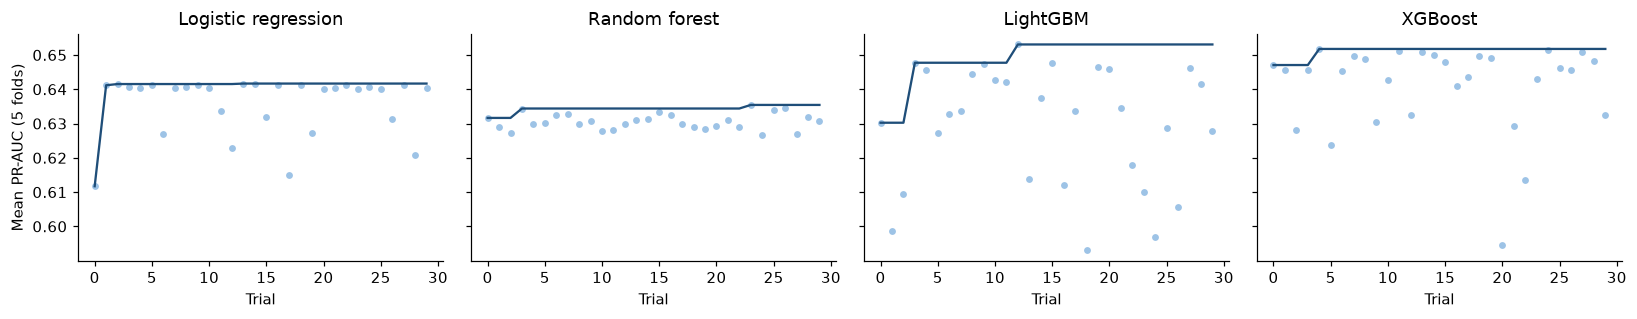

,C,colsample_bytree,learning_rate,max_depth,max_features,min_child_samples,min_child_weight,min_samples_leaf,n_estimators,num_leaves,penalty,reg_lambda,subsample
Logistic regression,0.12684325359651552,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,l1,NaN,NaN
Random forest,NaN,NaN,NaN,NaN,sqrt,NaN,NaN,38,500,NaN,NaN,NaN,NaN
LightGBM,NaN,0.6571190656089414,0.02922137072999514,NaN,NaN,72.0,NaN,NaN,276.0,6.0,NaN,2.615919624374859,0.8920258311276335
XGBoost,NaN,0.7974329355030264,0.029835618236403186,4.0,NaN,NaN,13.899804586138446,NaN,332.0,NaN,NaN,1.225414147186075,0.6781590399486216


In [12]:
best, trials = {}, {}
for algo in SIMPLICITY:
    best[("full", algo)], trials[algo] = tune(algo, "full", train, folds)
best[("demo", "logistic")], _ = tune("logistic", "demo", train, folds)   # demographics-only baseline
best[("demo", "dummy")] = {}                                              # always predicts the average rate

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, algo in zip(axes, SIMPLICITY):
    t = trials[algo]
    ax.scatter(t["trial"], t["pr_auc"], s=12, color="#9DC3E6")
    ax.plot(t["trial"], t["pr_auc"].cummax(), color=BLUE)
    ax.set(title=NAMES[algo], xlabel="Trial")
axes[0].set_ylabel("Mean PR-AUC (5 folds)")
plt.tight_layout(); plt.show()
pd.DataFrame({NAMES[a]: pd.Series(best[("full", a)]) for a in SIMPLICITY}).T.astype(str)

The search curves level off early, so a larger search budget would add little.

### 7.3 Model comparison

pr_auc       roc_auc       brier      
                               mean   std    mean   std  mean   std
model                                                              
LightGBM (full)               0.651 0.027   0.775 0.011 0.181 0.005
XGBoost (full)                0.650 0.027   0.776 0.012 0.180 0.006
Logistic regression (full)    0.641 0.029   0.764 0.015 0.184 0.007
Random forest (full)          0.633 0.031   0.769 0.012 0.190 0.004
Logistic regression (demo)    0.463 0.029   0.614 0.025 0.221 0.007
Baseline (prevalence) (demo)  0.356 0.015   0.500 0.000 0.230 0.004

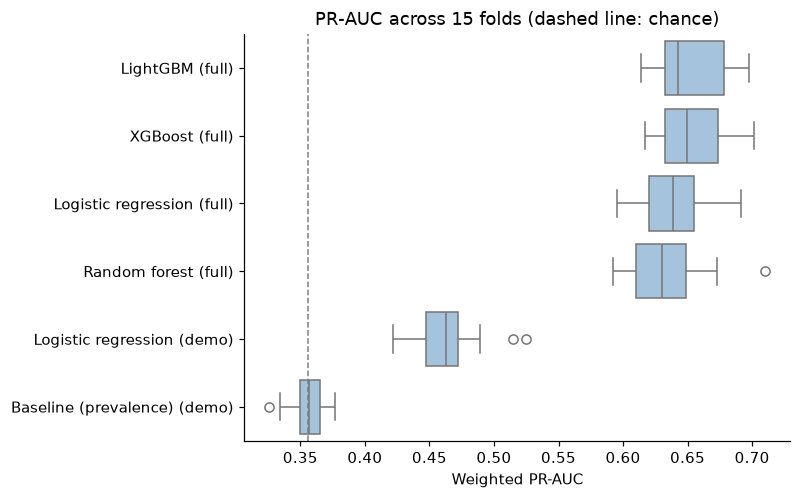

In [13]:
oof, scores = {}, []
for (fs, algo), params in best.items():
    oof[(fs, algo)], s = cross_validate(algo, fs, params, train, folds)
    scores.append(s.assign(model=f"{NAMES[algo]} ({fs})", algorithm=algo, feature_set=fs))
scores = pd.concat(scores)
cv = scores.groupby("model")[["pr_auc", "roc_auc", "brier"]].agg(["mean", "std"]).sort_values(("pr_auc", "mean"), ascending=False)
display(cv)

order = cv.index
sns.boxplot(data=scores, y="model", x="pr_auc", order=order, color="#9DC3E6")
plt.axvline(np.average(train["distress"], weights=train["weight"]), color=GREY, ls="--", lw=1)
plt.title("PR-AUC across 15 folds (dashed line: chance)"); plt.xlabel("Weighted PR-AUC"); plt.ylabel("")
plt.show()

All four tuned models clearly outperform the baselines. The demographics-only logistic regression is above chance (0.46 against 0.36) but far below the full models, and adding behaviour and controls raises PR-AUC to about 0.65. The four algorithms perform similarly, with the boosting models slightly ahead.

### 7.4 Model selection

The rule, fixed before the results: select the highest mean PR-AUC, but prefer a simpler model within 0.01 of the best (order of simplicity: logistic regression, random forest, LightGBM, XGBoost).

In [14]:
from Model.train import select_model

full = scores[scores["feature_set"] == "full"].groupby("algorithm")["pr_auc"].mean().rename("pr_auc_mean").to_frame()
full["gap_to_best"] = full["pr_auc_mean"].max() - full["pr_auc_mean"]
chosen = select_model(full)
display(full.sort_values("pr_auc_mean", ascending=False))
print("Chosen model:", NAMES[chosen])

,pr_auc_mean,gap_to_best
algorithm,,
lightgbm,0.651,0.000
xgboost,0.650,0.001
logistic,0.641,0.010
random_forest,0.633,0.018


Chosen model: LightGBM


LightGBM has the highest mean PR-AUC. Logistic regression falls just outside the 0.01 margin, so LightGBM is selected; the difference is small, and logistic regression remains a reasonable, more transparent alternative.

### 7.5 Added value of borrowing behaviour (H3)

LightGBM is tuned on demographics only and on demographics plus borrowing behaviour, and both are compared on the same folds. The 95% interval comes from 500 cluster bootstrap resamples.

In [15]:
from Model.train import h3_gain

for fs in ("demo", "demo_beh"):
    best[(fs, chosen)], _ = tune(chosen, fs, train, folds)
    oof[(fs, chosen)], _ = cross_validate(chosen, fs, best[(fs, chosen)], train, folds)
h3 = h3_gain(train, oof[("demo", chosen)], oof[("demo_beh", chosen)])
print(f"PR-AUC gain from borrowing behaviour: {h3['gain']:.3f} (95% CI {h3['ci_low']:.3f} to {h3['ci_high']:.3f})")

PR-AUC gain from borrowing behaviour: 0.098 (95% CI 0.067 to 0.129)


The gain is about 0.10, five times the 0.02 threshold, and the interval lies well above zero. **H3 is supported:** digital borrowing behaviour adds clear predictive value beyond demographic characteristics.

### 7.6 Calibration and threshold

Because the API reports probabilities, these must be well calibrated. Platt scaling and isotonic regression are compared on the out-of-fold predictions (fitted on half of the clusters, evaluated on the other half), and the threshold that maximises F1 is selected.

Class imbalance (36% against 64%) is not addressed with SMOTE or class weights: synthetic rows have no survey weight or cluster, and reweighting inflates probabilities. The threshold is adjusted instead.

,Brier score (lower is better)
platt,0.179
isotonic,0.179
uncalibrated,0.179


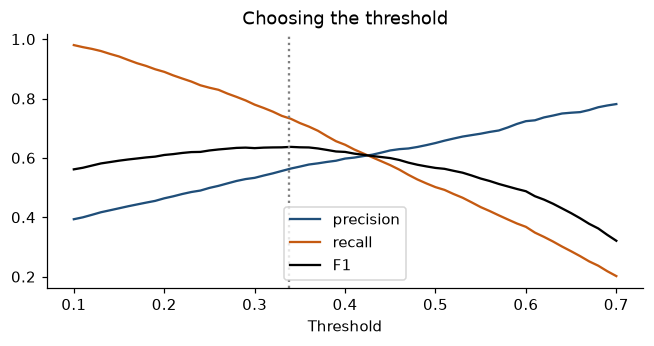

Calibration: platt; threshold = 0.338 (treats a missed case as about 2.0 times as costly as a false alarm)


In [16]:
from Model.train import fit_calibrator, best_threshold, N_REPEATS
from Model.components import calibrate

p = oof[("full", chosen)].reshape(-1)
y = np.tile(train["distress"].to_numpy(), N_REPEATS)
wt = np.tile(train["weight"].to_numpy(), N_REPEATS)
g = np.tile(train["cluster"].to_numpy(), N_REPEATS)
calibrator, method, brier = fit_calibrator(p, y, wt, g)
display(pd.Series(brier, name="Brier score (lower is better)").to_frame())
p_cal = calibrate(calibrator, method, p)
threshold = best_threshold(y, p_cal, wt)

from sklearn.metrics import precision_score, recall_score, f1_score
grid = np.linspace(0.1, 0.7, 61)
curve = pd.DataFrame({"precision": [precision_score(y, p_cal >= t, sample_weight=wt) for t in grid],
                      "recall": [recall_score(y, p_cal >= t, sample_weight=wt) for t in grid],
                      "F1": [f1_score(y, p_cal >= t, sample_weight=wt) for t in grid]}, index=grid)
ax = curve.plot(figsize=(7, 3), color=[BLUE, ORANGE, "black"], title="Choosing the threshold")
ax.axvline(threshold, color=GREY, ls=":"); ax.set_xlabel("Threshold"); plt.show()
print(f"Calibration: {method}; threshold = {threshold:.3f} "
      f"(treats a missed case as about {(1 - threshold) / threshold:.1f} times as costly as a false alarm)")

The three Brier scores agree to three decimal places, as the raw LightGBM scores are already well calibrated; Platt scaling is lowest by a very small margin and is retained. The selected threshold implies that a missed distressed borrower is treated as about twice as costly as a false alarm, which suits a tool for targeting support.

### 7.7 Final model

All models are refitted on the full training set, and the chosen model is saved with its calibrator and threshold as one bundle (`Model/model.joblib`).

In [17]:
import joblib, json
from Model.train import MODEL_DIR, RESULTS

y_tr = train["distress"].to_numpy()
finals = {(fs, a): make_model(a, fs, prm).fit(train[columns(fs)], y_tr) for (fs, a), prm in best.items()}
bundle = {"pipeline": finals[("full", chosen)], "calibrator": calibrator, "calibration": method,
          "threshold": threshold, "features": columns("full"), "algorithm": chosen}
joblib.dump(bundle, MODEL_DIR / "model.joblib", compress=3)
joblib.dump(finals, RESULTS / "all_models.joblib", compress=3)
print("Saved Model/model.joblib")

Saved Model/model.joblib


## 8. Test-set evaluation

The test clusters are now used, once. Intervals come from 1,000 cluster bootstrap resamples.

In [18]:
from Model.evaluate import test_metrics, compare_models, plots
from Model.components import predict_proba

p_raw_test = bundle["pipeline"].predict_proba(test[bundle["features"]])[:, 1]
p_test = predict_proba(bundle, test)
metrics = test_metrics(test, p_raw_test, p_test, threshold)
display(metrics)

,estimate,ci_low,ci_high
pr_auc,0.642,0.585,0.698
roc_auc,0.771,0.731,0.806
brier,0.187,0.171,0.203
precision,0.573,0.518,0.635
recall,0.713,0.661,0.763
f1,0.636,0.590,0.678
share_flagged,0.468,0.431,0.504
chance (prevalence),0.376,0.376,0.376


In [19]:
cv_means = scores.groupby(["algorithm", "feature_set"])["pr_auc"].mean().rename("pr_auc_mean").reset_index()
display(compare_models(test, finals, cv=cv_means))

,model,test_pr_auc,test_roc_auc,cv_pr_auc
2,LightGBM (full),0.642,0.771,0.651
1,Random forest (full),0.637,0.761,0.633
3,XGBoost (full),0.637,0.767,0.650
0,Logistic regression (full),0.635,0.763,0.641
7,LightGBM (demo_beh),0.557,0.699,NaN
4,Logistic regression (demo),0.463,0.590,0.463
6,LightGBM (demo),0.448,0.585,NaN
5,Baseline (prevalence) (demo),0.376,0.500,0.356


The model ranks distressed borrowers well on the test set: PR-AUC is about 0.64 against a chance level of 0.38. The test score is close to the cross-validation score, so tuning did not overfit. At the selected threshold the model identifies about 7 in 10 distressed borrowers, and slightly over half of those flagged are in distress. The tuned models give very similar test results, consistent with cross-validation.

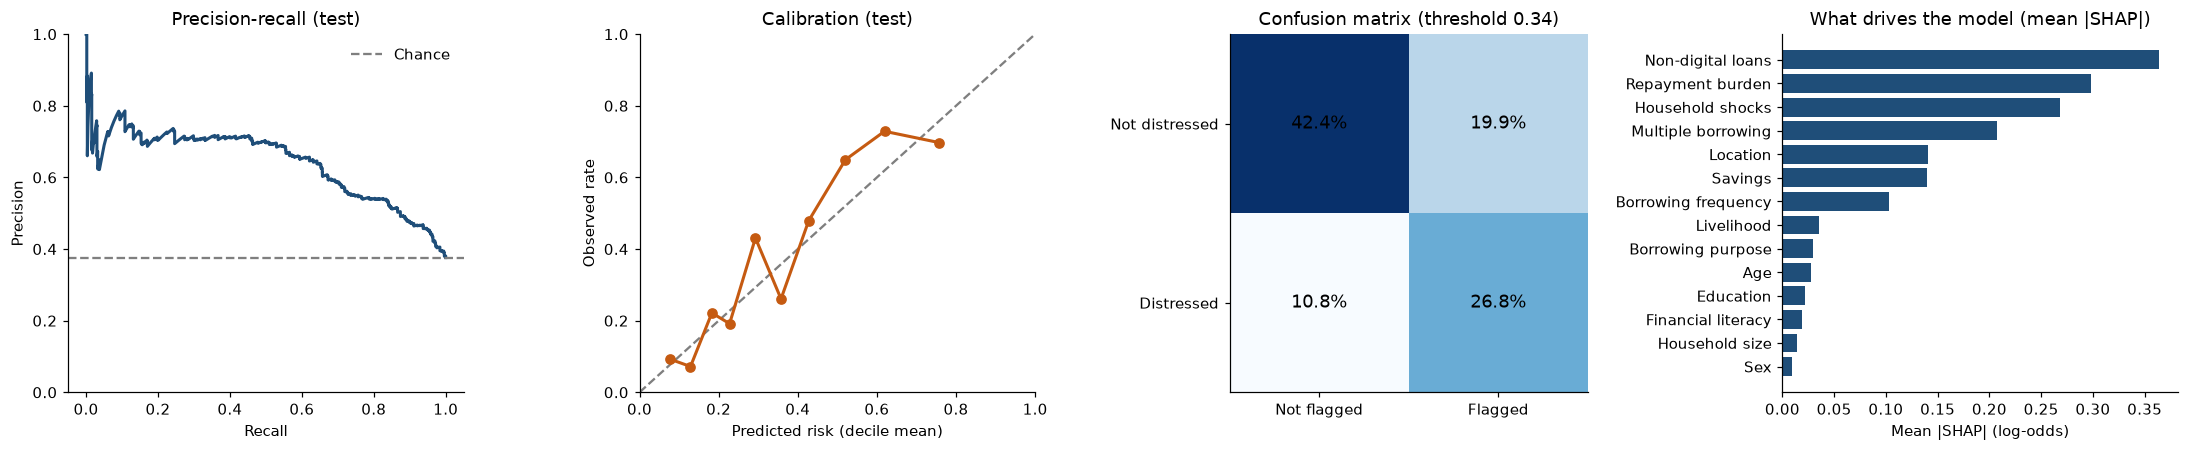

In [20]:
from Model.components import shap_by_group

shap_train = shap_by_group(bundle["pipeline"], train[bundle["features"]])
shap_importance = shap_train.abs().mean()
fig = plots(test, p_raw_test, p_test, threshold, shap_importance)
plt.show()

The calibration curve lies close to the diagonal, so a predicted 40% corresponds to roughly 40% observed distress. The confusion matrix shows the trade-off at the threshold: some false alarms in exchange for identifying most distressed borrowers.

**Missed cases.** Distressed borrowers missed by the model are compared with those it identified.

In [21]:
test_view = test.assign(flag=p_test >= threshold)
missed = test_view[(test_view["distress"] == 1) & ~test_view["flag"]]
found = test_view[(test_view["distress"] == 1) & test_view["flag"]]
cols = ["nondigital_loans", "shocks", "outstanding_loans", "repayment_burden", "has_savings"]
pd.DataFrame({"Found (true positives)": found[cols].mean(), "Missed (false negatives)": missed[cols].mean()})

,Found (true positives),Missed (false negatives)
nondigital_loans,1.646,0.562
shocks,1.381,0.514
outstanding_loans,1.651,1.289
repayment_burden,1.180,0.208
has_savings,0.772,0.764


Missed borrowers resemble non-distressed borrowers: fewer non-digital credit products, fewer shocks and lighter repayment burdens. Their distress may stem from factors the survey does not capture, which limits attainable recall.

## 9. Explaining the model

SHAP values decompose each prediction into predictor contributions, grouped here by topic and shown for four key predictors.

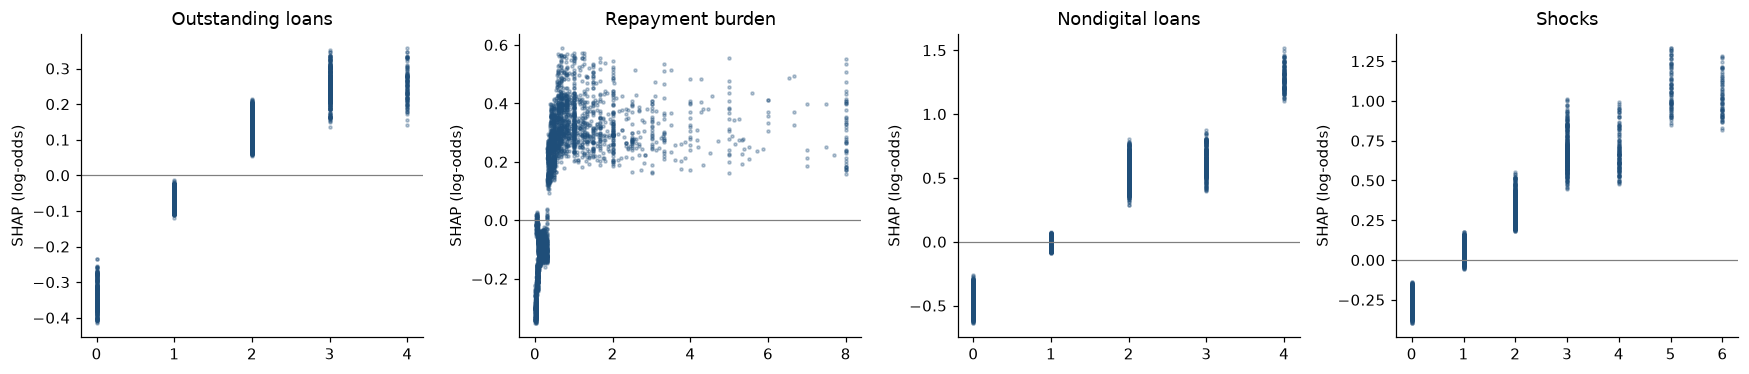

,mean |SHAP|
Non-digital loans,0.364
Repayment burden,0.298
Household shocks,0.268
Multiple borrowing,0.208
Location,0.141
Savings,0.139
Borrowing frequency,0.103
Livelihood,0.035
Borrowing purpose,0.029
Age,0.028


In [22]:
from Model.components import shap_by_group
import shap

pre, clf = bundle["pipeline"].named_steps["pre"], bundle["pipeline"].named_steps["clf"]
Xt = pd.DataFrame(pre.transform(train[bundle["features"]]), columns=pre.get_feature_names_out())
values = shap.TreeExplainer(clf).shap_values(Xt)
values = values[1] if isinstance(values, list) else values

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["counts__outstanding_loans", "skewed__repayment_burden", "numeric__nondigital_loans",
                          "numeric__shocks"]):
    i = list(Xt.columns).index(col)
    x = train[col.split("__")[1]].clip(upper=train[col.split("__")[1]].quantile(0.99))
    ax.scatter(x, values[:, i], s=4, alpha=0.3, color=BLUE)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set(title=col.split("__")[1].replace("_", " ").capitalize(), ylabel="SHAP (log-odds)")
plt.tight_layout(); plt.show()
shap_importance.sort_values(ascending=False).rename("mean |SHAP|").to_frame()

The strongest predictor is the number of **non-digital credit products** (a control), followed by repayment burden, household shocks and multiple digital borrowing; risk rises with each. Financial literacy and borrowing purpose contribute little.

## 10. Fairness and robustness

**Fairness.** Recall is compared across groups, and a gap of more than 0.05 below overall recall is flagged.

In [23]:
from Model.evaluate import fairness, county_holdout

fair = fairness(test, p_test, threshold)
fair["flag"] = fair["recall_gap"] < -0.05
display(fair)

,group,level,n,observed_rate,mean_predicted,recall,recall_gap,auc,flag
0,sex,Female,771,0.390,0.367,0.729,0.016,0.784,False
1,sex,Male,630,0.363,0.336,0.696,-0.017,0.759,False
2,residence,Rural,792,0.384,0.377,0.751,0.038,0.767,False
3,residence,Urban,609,0.368,0.326,0.674,-0.039,0.775,False
4,age_group,16-24,191,0.316,0.300,0.583,-0.129,0.751,True
5,age_group,25-34,508,0.391,0.338,0.713,0.001,0.789,False
6,age_group,35-44,348,0.434,0.404,0.795,0.083,0.782,False
7,age_group,45-54,198,0.374,0.394,0.781,0.068,0.778,False
8,age_group,55+,156,0.277,0.319,0.528,-0.185,0.667,True
9,province,Central,187,0.369,0.341,0.762,0.049,0.841,False


Recall is lower for the youngest and oldest borrowers and for Nairobi, North Eastern and Rift Valley. These groups have lower distress rates, so under a single national threshold fewer of their members cross it. Predicted and observed rates are within about 5 percentage points for most groups; the model under-predicts for urban borrowers and those aged 25 to 34, and over-predicts for North Eastern, which has only 31 test borrowers, so its gap is uncertain. Group-specific thresholds are not used, as they would give the same score different meanings for different people.

**Transfer to new regions.** As planned in the proposal, the model is trained on some counties and evaluated on the rest, and compared with the cluster-based split.

In [24]:
county = county_holdout(train, chosen, best[("full", chosen)])
county.groupby("scheme")[["pr_auc", "chance"]].agg(["mean", "std"])

pr_auc       chance      
                  mean   std   mean   std
scheme                                   
Unseen clusters  0.653 0.027  0.357 0.031
Unseen counties  0.627 0.048  0.361 0.058

Performance on unseen counties is only slightly lower (about 0.63 against 0.65), indicating reasonable transfer to new regions.

## 11. Saving and serving the model

The saved bundle is served by the FastAPI service in `API/main.py`, which also runs in Docker (`docker compose up --build`). The API is called below with an example borrower.

In [25]:
meta = {"model": NAMES[chosen], "params": best[("full", chosen)], "calibration": method,
        "calibration_brier": brier, "threshold": threshold,
        "features": columns("full"), "h3": h3, "test": metrics["estimate"].to_dict(),
        "label": "Late/missed/no repayment (E2E 1-2) AND a hardship sacrifice (E2D 1, 3, 4, 7), past 12 months",
        "population": "Current digital credit borrowers, FinAccess 2024",
        "intended_use": "Group-level risk profiles; not for decisions about individual borrowers"}
(MODEL_DIR / "metadata.json").write_text(json.dumps(meta, indent=1, default=float))

import importlib
from fastapi.testclient import TestClient
import API.main
importlib.reload(API.main)

client = TestClient(API.main.app)
example = json.loads((ROOT / "API" / "example_request.json").read_text())
print("GET /health ->", client.get("/health").json())
print("POST /predict ->", json.dumps(client.post("/predict", json=example).json(), indent=1))
print("Invalid input (age 12) ->", client.post("/predict", json={**example, "age": 12}).status_code)

GET /health -> {'status': 'ok', 'model_loaded': True, 'model': 'LightGBM', 'threshold': 0.3378485193688632}
POST /predict -> {
 "distress_probability": 0.4102,
 "high_risk": true,
 "top_drivers": [
  {
   "factor": "Multiple borrowing",
   "effect": "raises risk"
  },
  {
   "factor": "Location",
   "effect": "lowers risk"
  },
  {
   "factor": "Savings",
   "effect": "raises risk"
  }
 ],
 "notice": "Group-level estimate for this type of borrower. Not for decisions about an individual loan applicant."
}
Invalid input (age 12) -> 422


## 12. Conclusions

- **Prevalence:** about 36% of Kenya's digital borrowers are in debt distress, highest among those aged 35 to 44, farmers and casual workers, and in Western and Coast.
- **Model:** LightGBM, with a test PR-AUC of about 0.64 (chance 0.38), good calibration, and about 7 in 10 distressed borrowers identified.
- **H3 supported:** borrowing behaviour adds about 0.10 PR-AUC over demographics.
- **Drivers:** non-digital credit, repayment burden, household shocks and multiple digital loans.
- **Use:** targeting support and supervision at group level, not individual credit decisions.

**Techniques not used**

| Technique | Reason |
|---|---|
| Deep learning | About 6,000 rows of tabular survey data, where tree models usually perform better |
| SMOTE / class weights | Synthetic rows have no survey weight; reweighting distorts probabilities |
| Time-based split | Single survey year; cluster and county splits used instead |
| Stacking | Models are within about 0.02 of each other; the added complexity is not justified |
| PCA | Few, interpretable predictors; components would be harder to explain |

**Limitations.** The survey is cross-sectional, so findings are associations rather than causes. Late repayment and hardship refer to any loan, not only digital loans. Repayment burden is missing for a third of borrowers. The model was evaluated within one survey year and should be revalidated on the next FinAccess round.